Research Questions
1. Did female passengers have a higher survival rate than male passengers?
2. Did passenger class influence the survival rate?
3. Was passenger age related to the chances of survival?


In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load Titanic dataset

df = sns.load_dataset('titanic')

print("Titanic dataset loaded successfully!")

Titanic dataset loaded successfully!


In [3]:
# Display number of rows and columns

print("Dataset Shape:", df.shape)

Dataset Shape: (891, 15)


In [4]:
# Display first five records

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [6]:
# Statistical summary of numerical columns

df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [8]:
# Calculate percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': missing_percentage
})

print(missing_summary)

             Missing Values  Missing Percentage
survived                  0            0.000000
pclass                    0            0.000000
sex                       0            0.000000
age                     177           19.865320
sibsp                     0            0.000000
parch                     0            0.000000
fare                      0            0.000000
embarked                  2            0.224467
class                     0            0.000000
who                       0            0.000000
adult_male                0            0.000000
deck                    688           77.216611
embark_town               2            0.224467
alive                     0            0.000000
alone                     0            0.000000


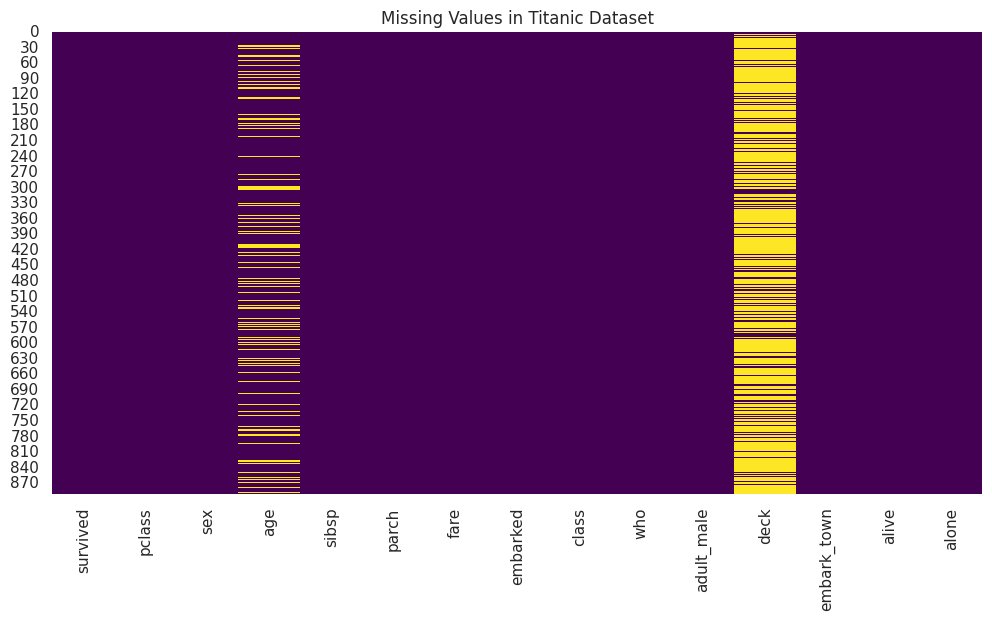

In [9]:
# Visualize missing values using a heatmap

plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap='viridis')

plt.title("Missing Values in Titanic Dataset")
plt.show()

In [10]:
# Fill missing age using median age based on class and sex

df['age'] = df.groupby(
    ['pclass', 'sex']
)['age'].transform(
    lambda x: x.fillna(x.median())
)

print("Missing age values after cleaning:", df['age'].isnull().sum())

Missing age values after cleaning: 0


In [11]:
# Fill missing embarked values using mode

df['embarked'] = df['embarked'].fillna(
    df['embarked'].mode()[0]
)

print("Missing embarked values:", df['embarked'].isnull().sum())

Missing embarked values: 0


In [12]:
# Drop columns with excessive missing values
# and redundant information

df.drop(columns=['deck', 'embark_town'], inplace=True)

print("Unnecessary columns removed successfully!")

Unnecessary columns removed successfully!


In [13]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 118


In [14]:
# Check remaining missing values

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:")
print(df.shape)

Missing Values After Cleaning:
survived      0
pclass        0
sex           0
age           0
sibsp         0
parch         0
fare          0
embarked      0
class         0
who           0
adult_male    0
alive         0
alone         0
dtype: int64

Dataset Shape After Cleaning:
(891, 13)


Data Cleaning Explanation
- Missing age values were replaced using the median age of passengers belonging to the same passenger class and sex.
- Missing embarked values were replaced using the most frequently occurring embarkation port.
- The deck column was removed because it contained a large proportion of missing values.
- The embark_town column was removed because it duplicated information available in the embarked column.
- Duplicate records were counted and inspected before deciding whether removal was necessary.

A total of 118 identical rows were detected using the duplicated() function. However, these records were retained because the dataset does not provide a unique passenger identifier to confirm whether they represent duplicate passengers or different passengers with identical information.

In [15]:
# Calculate survival rate by gender

gender_survival = df.groupby('sex')['survived'].agg(
    ['count', 'sum', 'mean']
)

gender_survival.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

gender_survival['Survival Rate'] *= 100

print(gender_survival.round(2))

        Total Passengers  Survivors  Survival Rate
sex                                               
female               314        233          74.20
male                 577        109          18.89


In [16]:
# Calculate survival rate by passenger class

class_survival = df.groupby('pclass')['survived'].agg(
    ['count', 'sum', 'mean']
)

class_survival.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

class_survival['Survival Rate'] *= 100

print(class_survival.round(2))

        Total Passengers  Survivors  Survival Rate
pclass                                            
1                    216        136          62.96
2                    184         87          47.28
3                    491        119          24.24


In [17]:
# Create age groups

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult',
            'Adult', 'Senior'],
    include_lowest=True
)

print(df[['age', 'age_group']].head(10))

    age    age_group
0  22.0  Young Adult
1  38.0        Adult
2  26.0  Young Adult
3  35.0  Young Adult
4  35.0  Young Adult
5  25.0  Young Adult
6  54.0        Adult
7   2.0        Child
8  27.0  Young Adult
9  14.0     Teenager


In [18]:
# Calculate survival rate by age group

age_survival = df.groupby(
    'age_group', observed=False
)['survived'].agg(
    ['count', 'sum', 'mean']
)

age_survival.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

age_survival['Survival Rate'] *= 100

print(age_survival.round(2))

             Total Passengers  Survivors  Survival Rate
age_group                                              
Child                      69         40          57.97
Teenager                   70         30          42.86
Young Adult               514        184          35.80
Adult                     216         83          38.43
Senior                     22          5          22.73


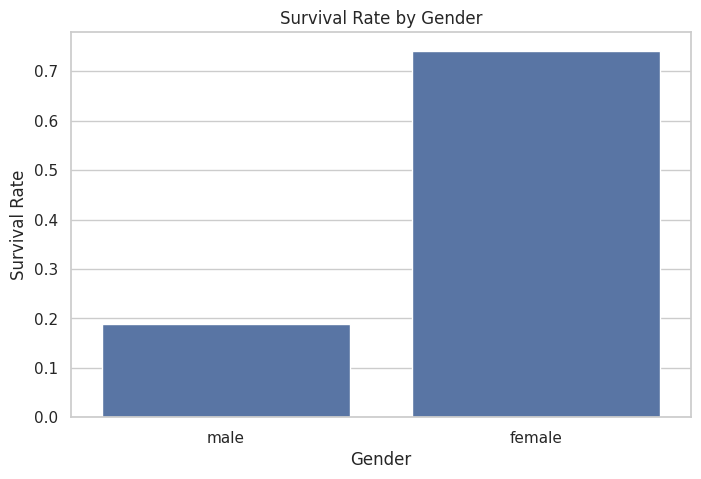

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='sex',
    y='survived',
    errorbar=None
)

plt.title('Survival Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')

plt.show()

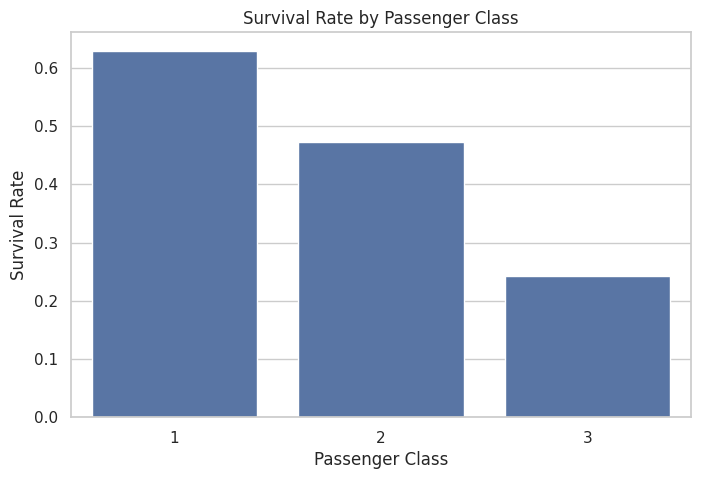

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='pclass',
    y='survived',
    errorbar=None
)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

plt.show()

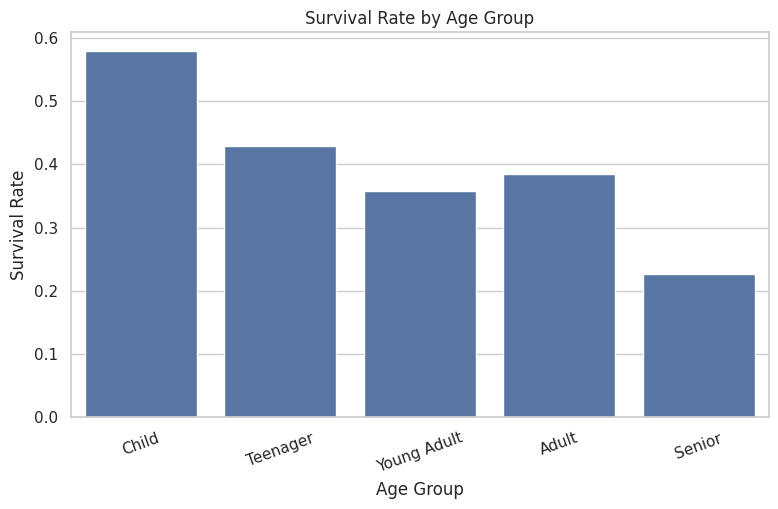

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='age_group',
    y='survived',
    errorbar=None
)

plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')

plt.xticks(rotation=20)
plt.show()

In [22]:
print(gender_survival.round(2))

        Total Passengers  Survivors  Survival Rate
sex                                               
female               314        233          74.20
male                 577        109          18.89


In [23]:
print(class_survival.round(2))

        Total Passengers  Survivors  Survival Rate
pclass                                            
1                    216        136          62.96
2                    184         87          47.28
3                    491        119          24.24


# Titanic Dataset – Exploratory Data Analysis (EDA)

## Project Overview

This project focuses on performing Exploratory Data Analysis (EDA) on the Titanic passenger dataset using Python. The main objective is to understand passenger characteristics, identify patterns in survival rates, and extract meaningful statistical insights.

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Data Cleaning

The original dataset contained 891 passenger records and 15 columns.

The following preprocessing steps were performed:

- Missing age values were replaced using the median age grouped by passenger class and sex.
- Missing embarked values were replaced with the most frequently occurring value.
- The deck column was removed because it contained many missing values.
- The embark_town column was removed because it duplicated information in the embarked column.
- A total of 118 identical rows were detected. They were retained because identical records could represent different passengers.

After cleaning, the dataset contained 891 records and 13 columns, with no remaining missing values.

## Three Major Findings

**1. Gender and Survival**

Female passengers had a survival rate of 74.20%, while male passengers had a survival rate of 18.89%. This shows a substantial difference in survival outcomes between genders.

**2. Passenger Class and Survival**

First-class passengers had the highest survival rate of 62.96%, followed by second-class passengers at 47.28%. Third-class passengers had the lowest survival rate of 24.24%.

**3. Age Group and Survival**

Children had the highest survival rate of 57.97%, whereas senior passengers had the lowest survival rate of 22.73%.

## Conclusion

The exploratory data analysis revealed meaningful patterns